# **Egg Fertility Detection — YOLOv11 Instance Segmentation**

This notebook implements an **instance segmentation** pipeline for classifying chicken eggs into **fertile** and **infertile** categories using **YOLOv11** from the [Ultralytics](https://docs.ultralytics.com/) library.

The dataset contains ~200 candling images annotated with **polygon segmentation masks** in YOLO format.

**Pipeline Overview:**
1. Mount Google Drive & define dataset path
2. Explore the dataset structure and annotations
3. Generate `dataset.yaml` programmatically
4. Install & import Ultralytics
5. Train YOLOv11 segmentation model
6. Evaluate on test split & visualize predictions

---
## **1. Mount Google Drive & Define Paths**

In [45]:
import os

# Menggunakan path folder tempat notebook ini berada secara otomatis
base_path = os.getcwd()

# Verifikasi struktur direktori
for split in ['train', 'valid', 'test']:
    img_dir = os.path.join(base_path, split, 'images')
    lbl_dir = os.path.join(base_path, split, 'labels')
    
    n_imgs = len(os.listdir(img_dir)) if os.path.exists(img_dir) else 0
    n_lbls = len(os.listdir(lbl_dir)) if os.path.exists(lbl_dir) else 0
    print(f"{split:>6s} — images: {n_imgs}, labels: {n_lbls}")

 train — images: 139, labels: 139
 valid — images: 40, labels: 40
  test — images: 19, labels: 19


---
## **2. Explore Dataset & Annotations**

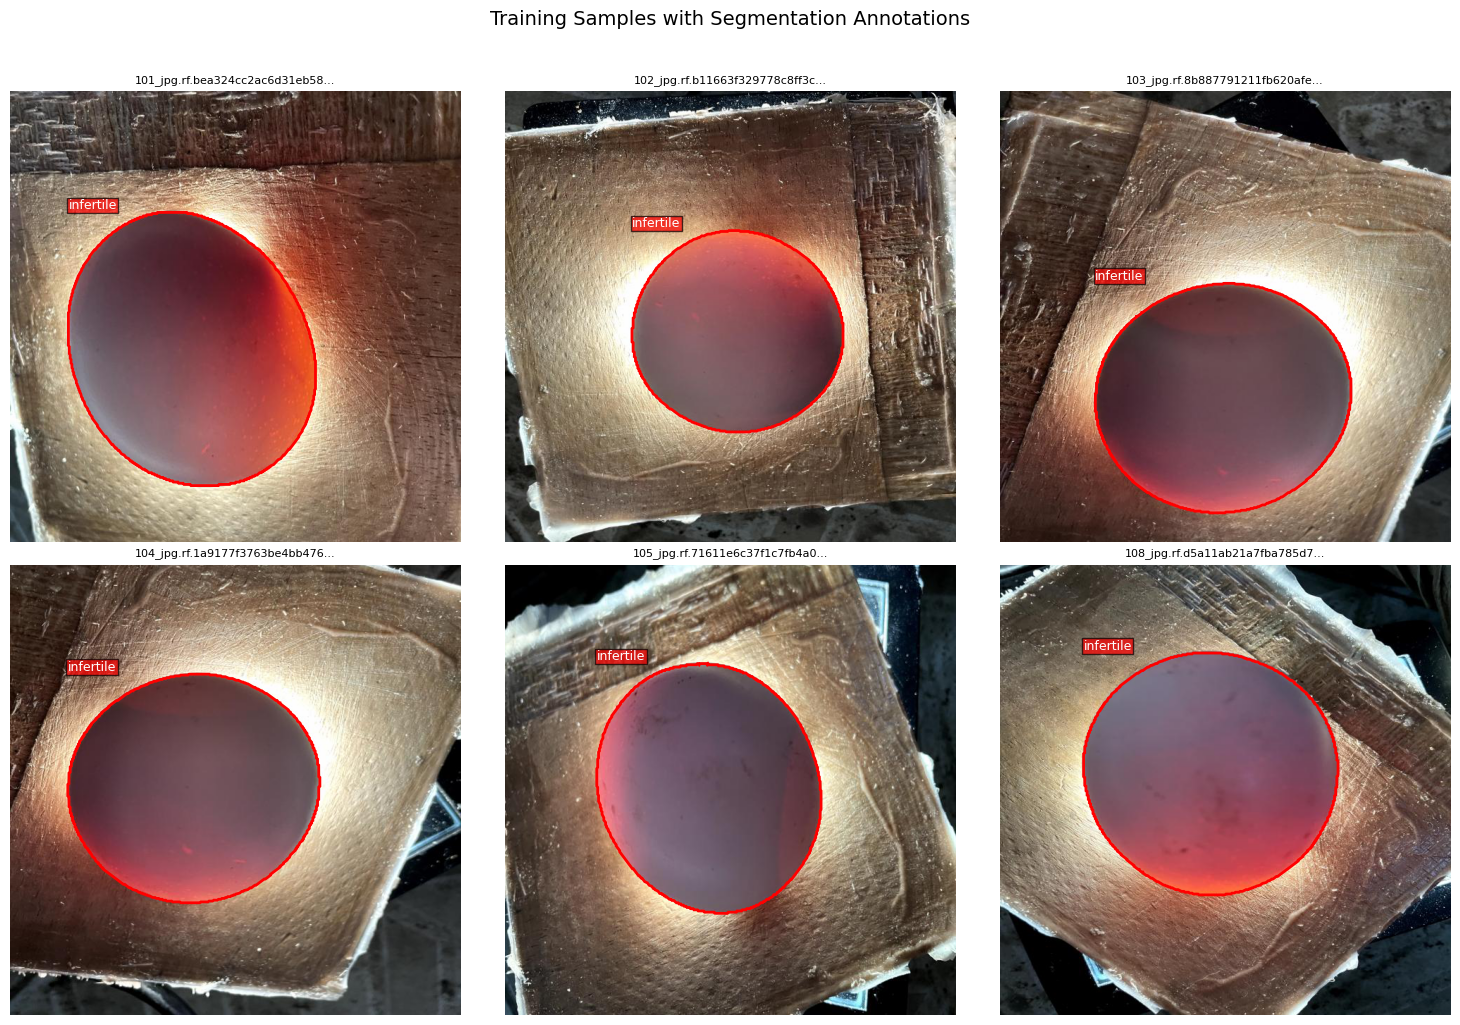

In [46]:
import os  # <--- PERBAIKAN: Wajib ditambahkan agar fungsi os.path bisa berjalan
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import numpy as np

# Pastikan base_path sudah didefinisikan (menggunakan path lokal proyek Anda)
base_path = r"D:\PROJECT\Web\python\egg-fertile-infertile"

def parse_yolo_seg_label(label_path):
    """Parse a YOLO segmentation label file.
    Returns list of (class_id, xs, ys) tuples.
    """
    annotations = []
    if not os.path.exists(label_path):
        return annotations
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls_id = int(parts[0])
            coords = list(map(float, parts[1:]))
            
            # coords adalah x1, y1, x2, y2, ... (normalized)
            xs = coords[0::2] # Mengambil koordinat X (indeks genap)
            ys = coords[1::2] # Mengambil koordinat Y (indeks ganjil)
            annotations.append((cls_id, xs, ys))
    return annotations

# Visualisasi beberapa sampel training dengan poligon segmentasinya
class_names = {0: 'infertile', 1: 'fertile'}
colors = {0: 'red', 1: 'lime'}

img_dir = os.path.join(base_path, 'train', 'images')
lbl_dir = os.path.join(base_path, 'train', 'labels')
img_files = sorted([f for f in os.listdir(img_dir) if f.endswith(('.jpg', '.png'))])

# Membuat grid visualisasi 2 baris x 3 kolom
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, img_file in zip(axes.flat, img_files[:6]):
    img = Image.open(os.path.join(img_dir, img_file))
    w, h = img.size
    ax.imshow(img)

    lbl_file = os.path.splitext(img_file)[0] + '.txt'
    anns = parse_yolo_seg_label(os.path.join(lbl_dir, lbl_file))

    for cls_id, xs, ys in anns:
        # Proses Denormalisasi koordinat dari skala 0-1 ke skala Piksel
        px = [x * w for x in xs]
        py = [y * h for y in ys]
        
        # Menggambar garis poligon pembungkus embrio telur
        polygon = plt.Polygon(list(zip(px, py)),
                              fill=False, edgecolor=colors.get(cls_id, 'yellow'),
                              linewidth=2)
        ax.add_patch(polygon)
        
        # Menampilkan teks label kelas di atas poligon
        ax.text(min(px), min(py) - 5,
                class_names.get(cls_id, str(cls_id)),
                color='white', fontsize=9,
                bbox=dict(facecolor=colors.get(cls_id, 'yellow'), alpha=0.7, pad=1))

    ax.set_title(img_file[:30] + '...', fontsize=8)
    ax.axis('off')

plt.suptitle('Training Samples with Segmentation Annotations', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [47]:
# Class distribution across splits
from collections import Counter

print("Class distribution per split:")
print("-" * 40)
for split in ['train', 'valid', 'test']:
    lbl_dir = os.path.join(base_path, split, 'labels')
    counter = Counter()
    empty = 0
    for lbl_file in os.listdir(lbl_dir):
        if not lbl_file.endswith('.txt'):
            continue
        with open(os.path.join(lbl_dir, lbl_file), 'r') as f:
            content = f.read().strip()
            if not content:
                empty += 1
                continue
            for line in content.split('\n'):
                cls_id = int(line.split()[0])
                counter[cls_id] += 1
    dist_str = ', '.join([f"{class_names.get(k, k)}: {v}" for k, v in sorted(counter.items())])
    print(f"  {split:>6s} — {dist_str}  (empty labels: {empty})")

Class distribution per split:
----------------------------------------
   train — infertile: 72, fertile: 67  (empty labels: 0)
   valid — infertile: 18, fertile: 22  (empty labels: 0)
    test — infertile: 10, fertile: 9  (empty labels: 0)


---
## **3. Generate `dataset.yaml`**

YOLOv11 requires a `dataset.yaml` file that specifies:
- Root path to the dataset
- Relative paths to train/val/test image directories
- Class names mapping

In [48]:
import os
import yaml

# Pastikan base_path sudah diset ke folder lokal Windows Anda
base_path = r"D:\PROJECT\Web\python\egg-fertile-infertile"

# PERBAIKAN: Mengubah 'path' dari Google Drive ke variabel base_path lokal
dataset_config = {
    'path': base_path,          # <-- Menggunakan path lokal komputer Anda
    'train': 'train/images',    # Relatif terhadap folder di atas
    'val': 'valid/images',      # Relatif terhadap folder di atas
    'test': 'test/images',      # Relatif terhadap folder di atas
    'names': {
        0: 'infertile',
        1: 'fertile'
    }
}

# Menentukan lokasi penyimpanan file dataset.yaml
yaml_path = os.path.join(base_path, 'dataset.yaml')

# Menulis data ke dalam file dataset.yaml
with open(yaml_path, 'w') as f:
    yaml.dump(dataset_config, f, default_flow_style=False, sort_keys=False)

# Verifikasi hasil pembuatan file
print(f"dataset.yaml berhasil disimpan di: {yaml_path}")
print("--- Isi File dataset.yaml ---")
with open(yaml_path, 'r') as f:
    print(f.read())

dataset.yaml berhasil disimpan di: D:\PROJECT\Web\python\egg-fertile-infertile\dataset.yaml
--- Isi File dataset.yaml ---
path: D:\PROJECT\Web\python\egg-fertile-infertile
train: train/images
val: valid/images
test: test/images
names:
  0: infertile
  1: fertile



---
## **4. Install & Import Ultralytics**

In [12]:
!pip install -q ultralytics

In [49]:
import ultralytics
ultralytics.checks()

from ultralytics import YOLO

Ultralytics 8.4.83  Python-3.11.15 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
Setup complete  (12 CPUs, 15.7 GB RAM, 113.2/293.0 GB disk)


---
## **5. Train YOLOv11 Segmentation Model**

Since the annotations are **segmentation polygons**, we use the `yolo11n-seg.pt` pretrained model for instance segmentation.

In [14]:
!pip install --upgrade ultralytics

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ----------------------- ---------------- 0.8/1.3 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 1.3/1.3 MB 6.9 MB/s  0:00:00

  Attempting uninstall: ultralytics

    Found existing installation: ultralytics 8.2.30

    Uninstalling ultralytics-8.2.30:

      Successfully uninstalled ultralytics-8.2.30

   -------------------- ------------------- 1/2 [ultralytics]
   -------------------- ------------------- 1/2 [ultralytics]
   -------------------- ------------------- 1/2 [ultralytics]
   -------------------- ------------------- 1/2 [ultralytics]
   -------------------- ------------------- 1/2 [ultralytics]
   -------------------- ------------------- 1/2 [ultralytics]
   -------------------- ------------------- 1/2 [ultralytics]
   ---------------------------------------- 2/2 [ultralytics]



In [50]:
import os
from ultralytics import YOLO

# Mendefinisikan base path proyek Anda secara eksplisit
base_path = r"D:\PROJECT\Web\python\egg-fertile-infertile"

# 1. Load model YOLOv11 menggunakan path absolut ke file yang sudah didownload manual
model_path = os.path.join(base_path, 'yolo11n-seg.pt')
model = YOLO(model_path) 

# 2. Mulai training dengan memanfaatkan RTX 4050
results = model.train(
    data=os.path.join(base_path, 'dataset.yaml'), 
    epochs=50, 
    imgsz=640, 
    device=0,      # Menggunakan GPU RTX 4050
    workers=0,     # Mencegah error multiprocessing di Windows
    batch=16       # Mengatur batch size agar VRAM 6GB RTX 4050 tidak overload
)

New https://pypi.org/project/ultralytics/8.4.84 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.83  Python-3.11.15 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\PROJECT\Web\python\egg-fertile-infertile\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=D:\PROJECT\W

Results saved to: D:\PROJECT\Web\python\egg-fertile-infertile\runs\segment\train-2


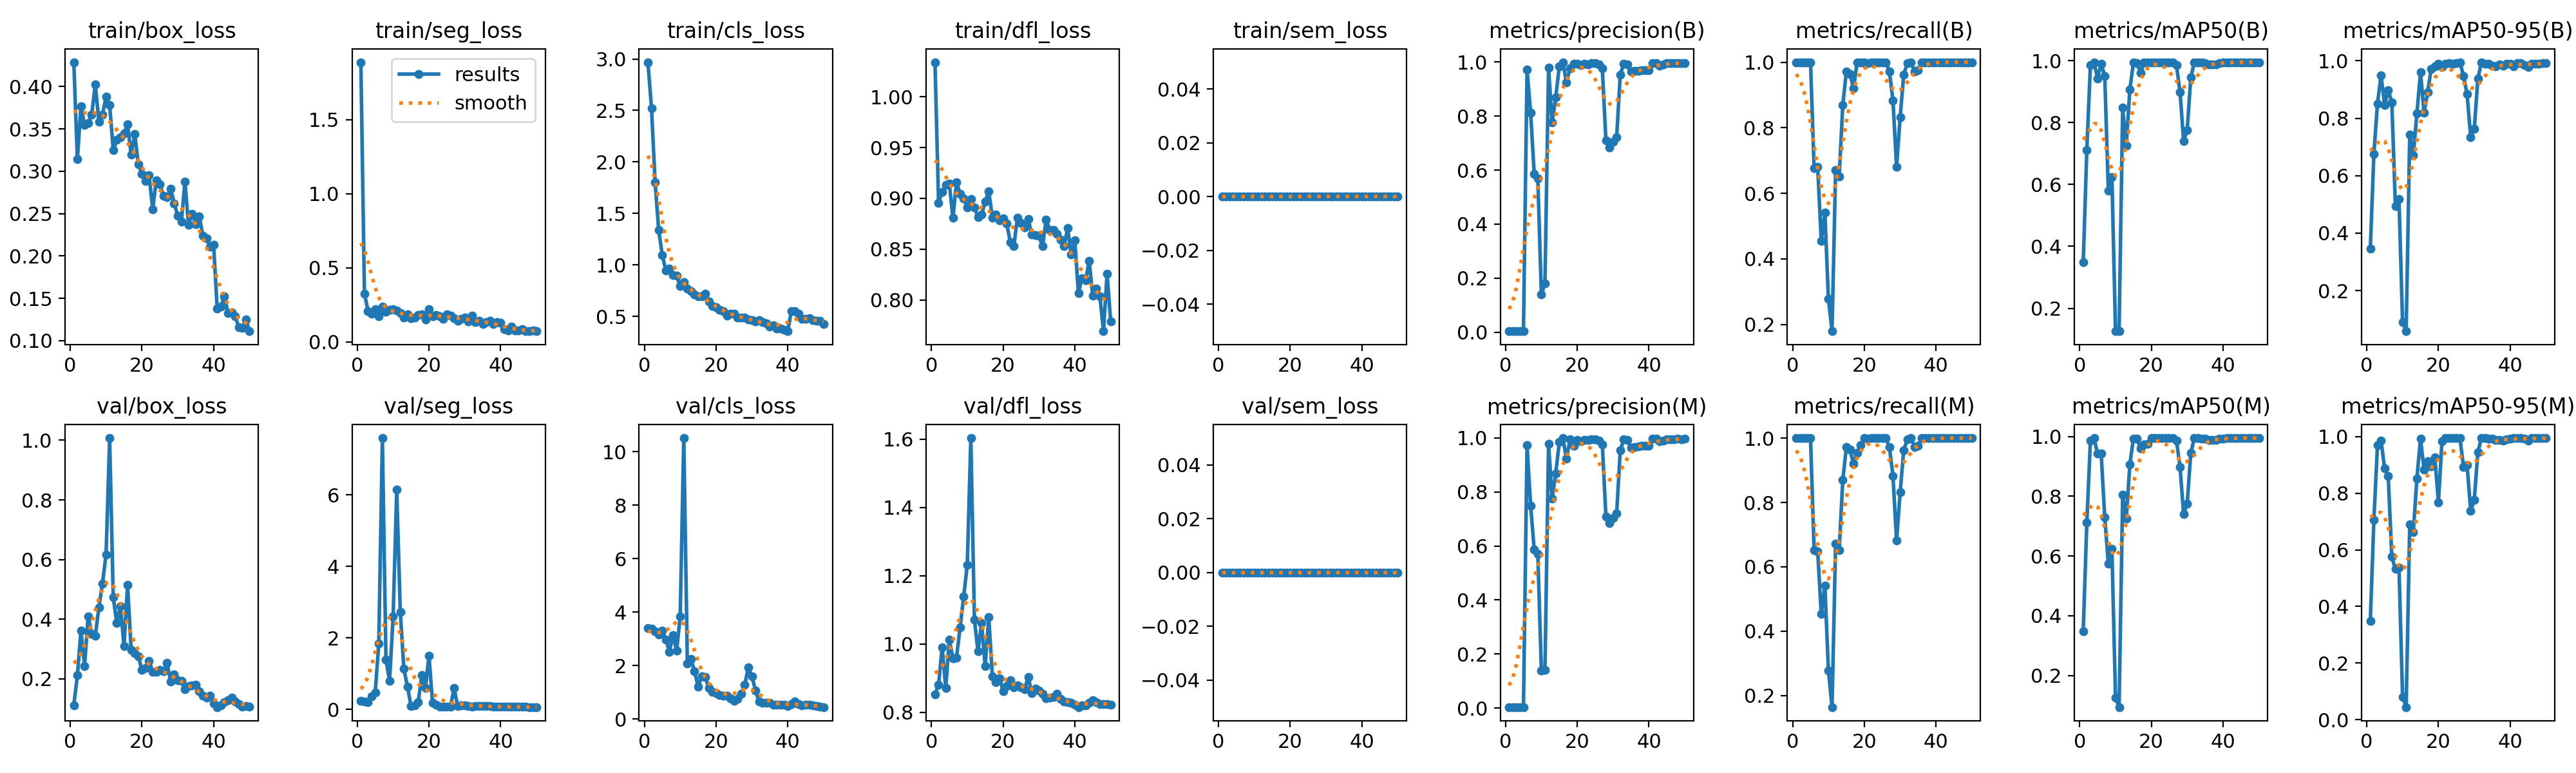

In [51]:
# Display training curves
from IPython.display import Image as IPImage, display

results_dir = results.save_dir
print(f"Results saved to: {results_dir}")

# Show training results plot
results_img = os.path.join(results_dir, 'results.png')
if os.path.exists(results_img):
    display(IPImage(filename=results_img, width=900))

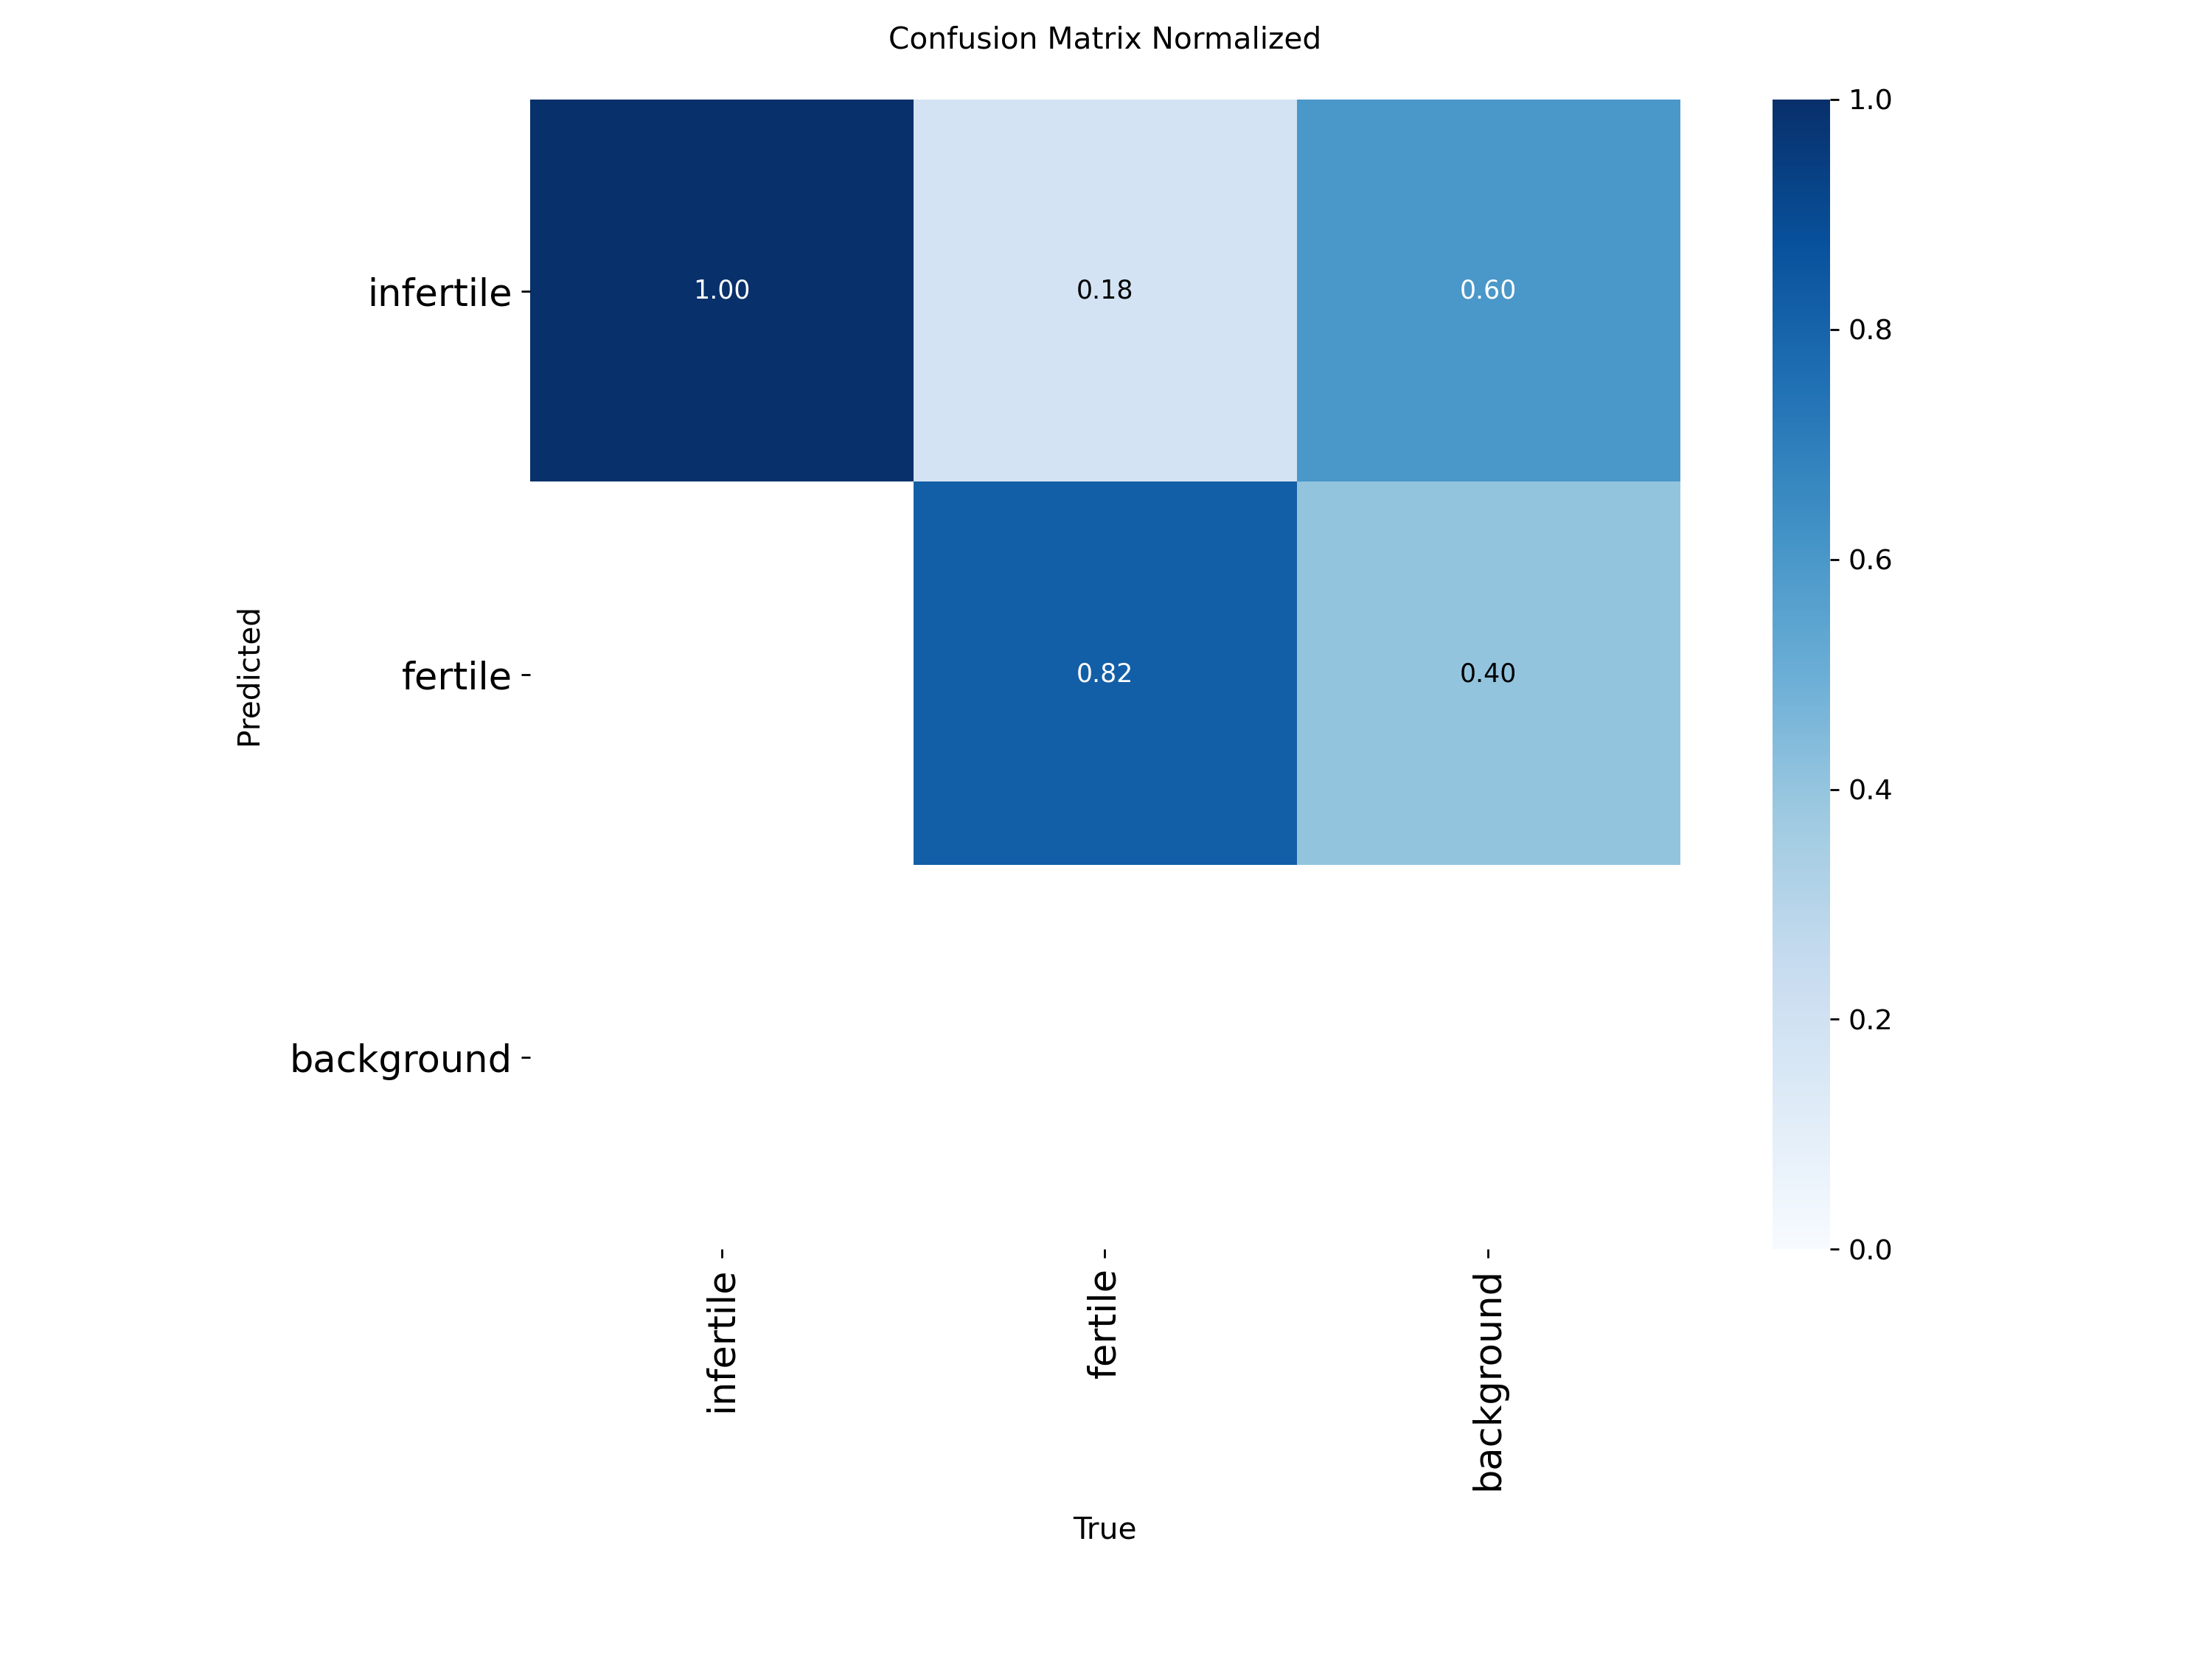

In [52]:
# Show confusion matrix
cm_img = os.path.join(results_dir, 'confusion_matrix_normalized.png')
if os.path.exists(cm_img):
    display(IPImage(filename=cm_img, width=600))
else:
    cm_img = os.path.join(results_dir, 'confusion_matrix.png')
    if os.path.exists(cm_img):
        display(IPImage(filename=cm_img, width=600))

---
## **6. Evaluate on Test Set**

In [53]:
# Load the best trained model
best_model_path = os.path.join(results_dir, 'weights', 'best.pt')
best_model = YOLO(best_model_path)

# Validate on the test split
test_metrics = best_model.val(
    data=yaml_path,
    split='test',
    device='0',
    plots=True,
)

print("\n" + "=" * 50)
print("TEST SET METRICS")
print("=" * 50)
print(f"  Box  mAP@50    : {test_metrics.box.map50:.4f}")
print(f"  Box  mAP@50-95 : {test_metrics.box.map:.4f}")
print(f"  Mask mAP@50    : {test_metrics.seg.map50:.4f}")
print(f"  Mask mAP@50-95 : {test_metrics.seg.map:.4f}")
print("=" * 50)

Ultralytics 8.4.83  Python-3.11.15 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11n-seg summary (fused): 114 layers, 2,834,958 parameters, 0 gradients, 9.6 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 7.12.5 MB/s, size: 49.3 KB)
val: Scanning D:\PROJECT\Web\python\egg-fertile-infertile\test\labels... 19 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 19/19 634.8it/s 0.0s
val: New cache created: D:\PROJECT\Web\python\egg-fertile-infertile\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.5s/it 5.0s<15.8s
                   all         19         19      0.966      0.994      0.995      0.995      0.966      0.994      0.995      0.995
             infertile         10         10      0.931          1      0.995      0.995      0.931          1      0.995      0.995
               fertile          9          9          1

---
## **7. Visualize Predictions on Test Images**

Berhasil memuat model terbaik (best.pt)!


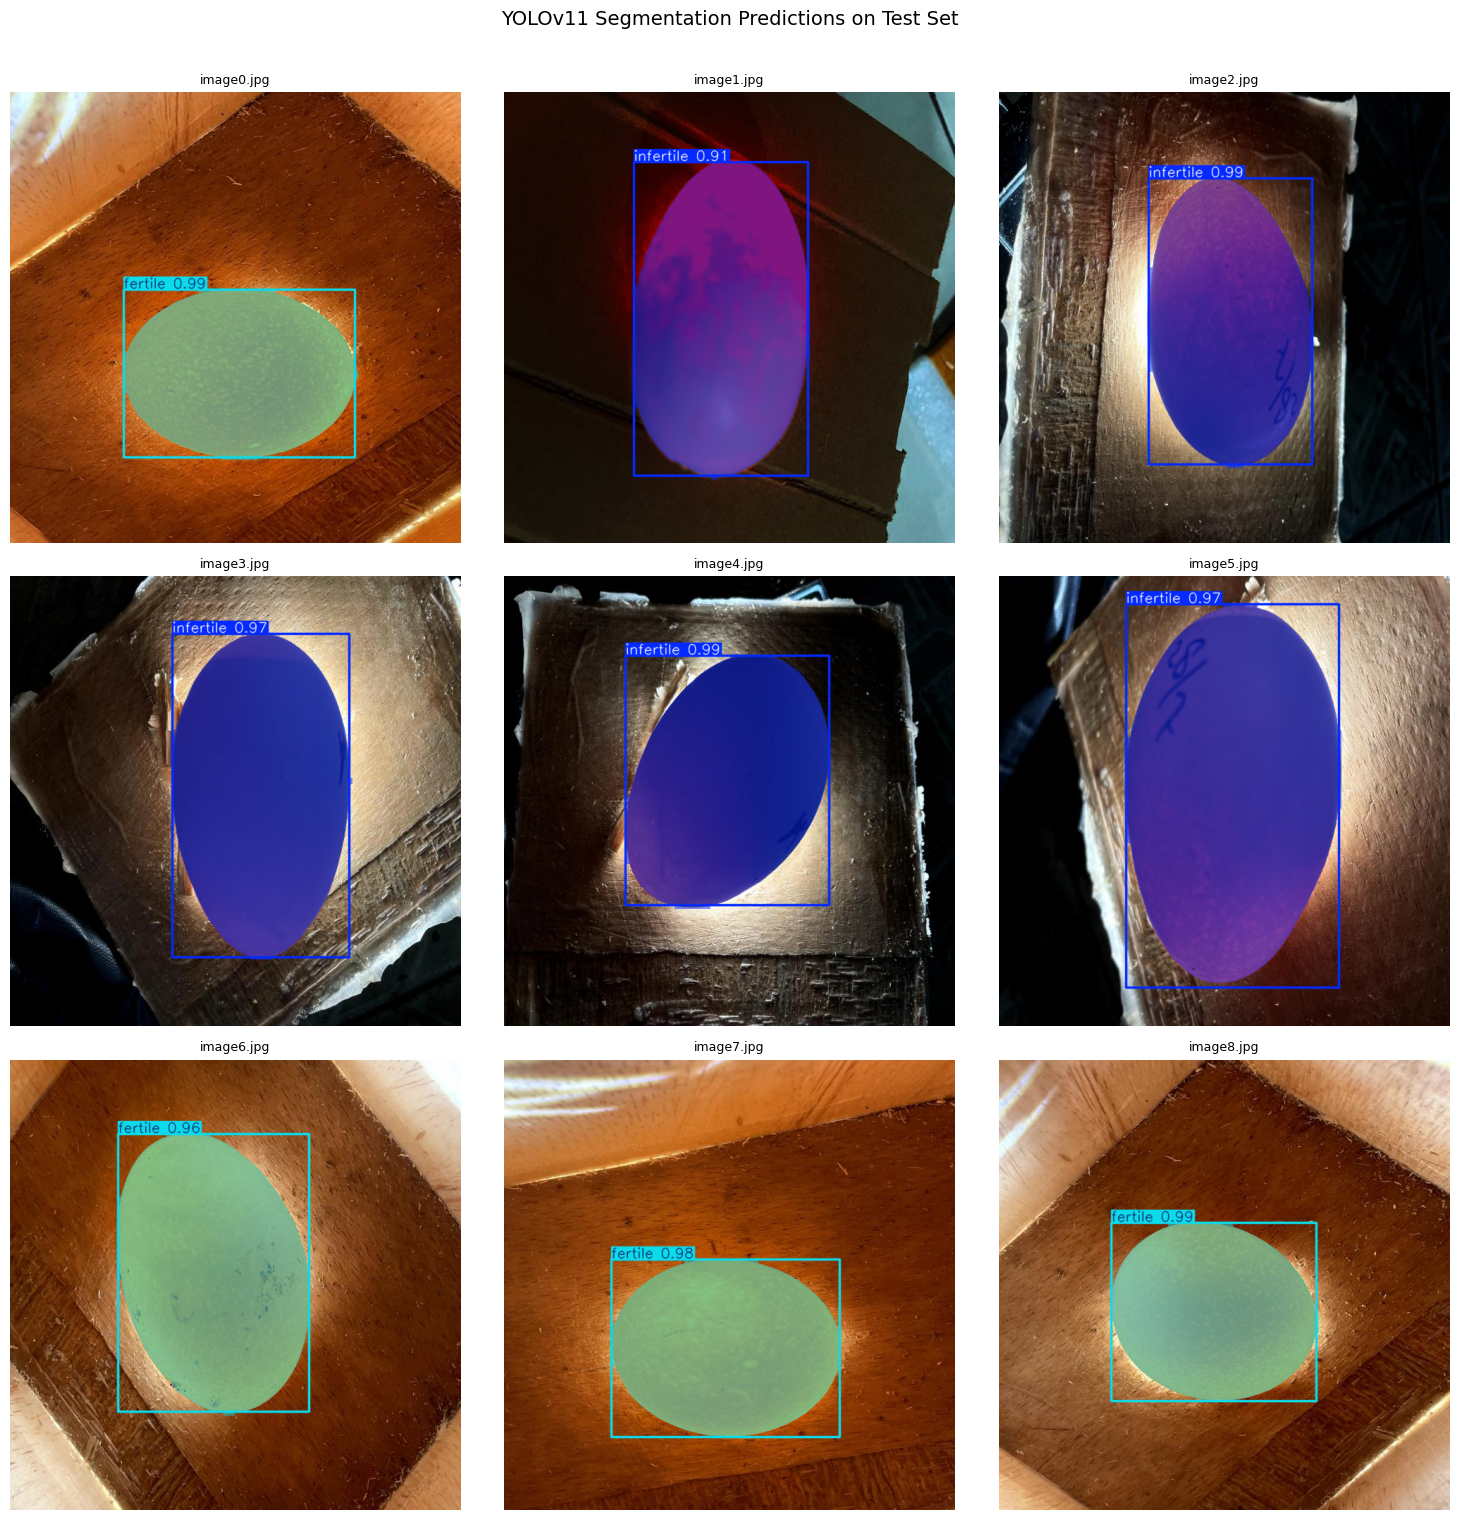

In [54]:
%matplotlib inline
import os
import random
import matplotlib.pyplot as plt
# ... sisa kode Anda yang lain ...

# 1. Definisikan ulang path utama proyek Anda
base_path = r"D:\PROJECT\Web\python\egg-fertile-infertile"

# 2. Ambil path file bobot terbaik hasil training Anda kemarin
# Catatan: Jika Anda melakukan training ulang berkali-kali, folder 'train' bisa berubah menjadi 'train2', 'train3', dst.
# Sesuaikan nama foldernya jika diperlukan.
best_weight_path = os.path.join(base_path, 'runs', 'segment', 'train', 'weights', 'best.pt')

# PERBAIKAN: Muat model dari hasil training terbaik
if os.path.exists(best_weight_path):
    best_model = YOLO(best_weight_path)
    print("Berhasil memuat model terbaik (best.pt)!")
else:
    # Jika file runs belum terbuat, gunakan objek 'model' yang sudah ada di memori sebelumnya
    best_model = model 
    print("File best.pt tidak ditemukan, menggunakan model di memori aktif.")

# 3. Ambil gambar dari folder test
test_img_dir = os.path.join(base_path, 'test', 'images')
test_images = sorted([os.path.join(test_img_dir, f)
                       for f in os.listdir(test_img_dir)
                       if f.endswith(('.jpg', '.png'))])

# Pastikan ada gambar di folder test sebelum sampling agar tidak crash
if len(test_images) == 0:
    print("Error: Tidak ada gambar berekstensi .jpg atau .png di folder test/images Anda!")
else:
    # Ambil sampel maksimal 9 gambar data uji
    n_samples = min(9, len(test_images))
    sample_images = random.sample(test_images, n_samples)

    # 4. Jalankan prediksi (Inference) menggunakan RTX 4050
    predictions = best_model.predict(
        source=sample_images,
        conf=0.25,
        iou=0.45,
        device=0,      # PERBAIKAN: Gunakan integer 0 (bukan string '0') agar sinkron dengan cuda
        verbose=False,
    )

    # 5. Plot hasil prediksi ke dalam grid visual
    ncols = 3
    nrows = (n_samples + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 5 * nrows))
    
    # Ratakan matriks axes agar mudah di-looping
    axes = axes.flat if n_samples > 1 else [axes]

    i = -1 # Inisialisasi awal untuk mencegah UnboundLocalError jika terjadi keanehan loop
    for i, (ax, result) in enumerate(zip(axes, predictions)):
        # result.plot() mengembalikan array gambar BGR yang sudah digambari poligon & kotak oleh YOLO
        annotated = result.plot()
        
        # Konversi warna dari BGR ke RGB agar tampil normal di matplotlib
        annotated_rgb = annotated[:, :, ::-1]
        ax.imshow(annotated_rgb)
        ax.set_title(os.path.basename(result.path), fontsize=9)
        ax.axis('off')

    # Sembunyikan subplot sisa yang tidak terpakai jika sampel kurang dari kelipatan 3
    for j in range(i + 1, len(list(axes))):
        axes[j].axis('off')
        axes[j].set_visible(False)

    plt.suptitle('YOLOv11 Segmentation Predictions on Test Set', fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()

In [15]:
# Detailed per-image prediction breakdown
print("Detailed predictions for sample test images:")
print("=" * 60)

for result in predictions:
    fname = os.path.basename(result.path)
    print(f"\n  Image: {fname}")

    if result.boxes is not None and len(result.boxes) > 0:
        for j in range(len(result.boxes)):
            cls_id = int(result.boxes.cls[j])
            conf = float(result.boxes.conf[j])
            cls_name = result.names[cls_id]
            bbox = result.boxes.xyxy[j].cpu().numpy().astype(int)
            has_mask = result.masks is not None and j < len(result.masks)
            mask_info = f"mask with {len(result.masks.xy[j])} points" if has_mask else "no mask"
            print(f"    [{j}] {cls_name} ({conf:.2f}) — bbox: {bbox}, {mask_info}")
    else:
        print("    No detections.")

print("\n" + "=" * 60)

Detailed predictions for sample test images:

  Image: image0.jpg
    [0] infertile (0.99) — bbox: [172 114 461 468], mask with 415 points

  Image: image1.jpg
    [0] infertile (0.98) — bbox: [ 85 199 542 427], mask with 438 points

  Image: image2.jpg
    [0] fertile (0.97) — bbox: [151 119 420 507], mask with 436 points

  Image: image3.jpg
    [0] fertile (0.99) — bbox: [159 232 450 485], mask with 358 points

  Image: image4.jpg
    [0] infertile (0.97) — bbox: [180  41 482 585], mask with 559 points

  Image: image5.jpg
    [0] fertile (0.96) — bbox: [153 106 424 500], mask with 435 points

  Image: image6.jpg
    [0] infertile (0.99) — bbox: [212 122 444 528], mask with 420 points

  Image: image7.jpg
    [0] infertile (0.99) — bbox: [125 107 532 481], mask with 516 points

  Image: image8.jpg
    [0] fertile (0.98) — bbox: [154  98 406 540], mask with 462 points
    [1] fertile (0.39) — bbox: [528 554 639 639], mask with 60 points



---
## **8. Export Model (Optional)**

Export the trained model to ONNX or other formats for deployment.

In [16]:
# Export to ONNX format (uncomment to run)
# best_model.export(format='onnx', imgsz=640, simplify=True)

print(f"Best model weights: {best_model_path}")
print(f"Training results  : {results_dir}")
print("\nDone! ✅")

Best model weights: D:\PROJECT\Web\python\egg-fertile-infertile\runs\segment\train\weights\best.pt
Training results  : D:\PROJECT\Web\python\egg-fertile-infertile\runs\segment\train

Done! ✅
